<a href="https://colab.research.google.com/github/klsay/mscai/blob/main/MSC_AI_CWork1_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MSC AI Course Work Assignment 1

In [23]:
# importing the libraries
import os
import shutil
import numpy as np
import pandas as pd
import seaborn as sns
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from scipy.stats import skew
from imblearn.over_sampling import RandomOverSampler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.neural_network import MLPClassifier
from imblearn.over_sampling import RandomOverSampler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, f1_score, balanced_accuracy_score, confusion_matrix
from sklearn.preprocessing import TargetEncoder, LabelEncoder, OrdinalEncoder, StandardScaler



In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

# 1. Load dataset

In [26]:
# This is the directory of the capstone project
data_dir='/content/drive/My Drive/MscAI/Dataset'

# read the csv file, load dataset
df = pd.read_csv(data_dir + '/' + 'dataset_coursework1.csv', low_memory = False)
raw_df = pd.read_csv(data_dir + '/' + 'dataset_coursework1.csv', low_memory = False)

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print(df.columns.tolist())
print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")

Rows: 508106, Columns: 30
['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']
Dataset Shape: 508,106 rows x 30 columns



In [27]:
print("First (Top) 10 rows")
display(df.head(10))
print("Bottom (last) 5 rows")
display(df.tail(5))
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")

First (Top) 10 rows


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,...,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"
5,201590741,2902,260040313,09/14/2026 05:34:24 PM,09/14/2026 05:34:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,094,8200.0,NaN,GEORGIA,NaN,AVE,38.99163,-77.0266,3D,"(38.9916, -77.0266)"
6,201590733,9105,260040296,NaN,09/14/2026 04:31:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,073,9000.0,NaN,OLD GEORGETOWN,NaN,RD,39.00170,-77.1097,2D,"(39.0017, -77.1097)"
7,201590735,2610,260040293,09/14/2026 03:54:56 PM,09/14/2026 03:54:00 PM,NaN,26F,1,Crime Against Property,Identity Theft,...,476,23200.0,NaN,STRINGTOWN,NaN,RD,39.23749,-77.2779,5D,"(39.2375, -77.2779)"
8,201590739,9107,260040301,09/14/2026 03:54:06 PM,09/14/2026 03:54:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,721,15000.0,NaN,BROSCHART,NaN,RD,39.10179,-77.2003,6D,"(39.1018, -77.2003)"
9,201590738,1399,260040292,09/14/2026 03:39:27 PM,09/14/2026 03:39:00 PM,NaN,13B,1,Crime Against Person,Simple Assault,...,465,13400.0,NaN,WISTERIA,NaN,DR,39.18195,-77.2787,5D,"(39.182, -77.2787)"


Bottom (last) 5 rows


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
508101,201089700,2308,16036427,NaN,7/1/2016 0:00,7/5/2016 0:00,23D,1,Crime Against Property,Theft from Building,...,036,4100.0,NaN,LELAND,NaN,ST,38.98565,-77.0818,2D,"(38.9857, -77.0818)"
508102,201248224,9105,190033731,07/16/2019 10:55:43 AM,7/1/2016 0:00,NaN,90Z,1,Crime Against Society,All Other Offenses,...,276,1.0,NaN,MONROE,NaN,PL,39.08354,-77.1469,1D,"(39.0835, -77.1469)"
508103,201100330,2589,16048345,NaN,7/1/2016 0:00,07/31/2016 12:00:00 AM,250,1,Crime Against Property,Counterfeiting/Forgery,...,276,1.0,NaN,COURTHOUSE,NaN,SQ,39.08418,-77.1529,1D,"(39.0842, -77.1529)"
508104,201103549,2699,16053730,NaN,7/1/2016 0:00,09/30/2016 11:59:00 PM,26A,1,Crime Against Property,False Pretenses/Swindle/Confidence Game,...,298,13100.0,NaN,OKINAWA,NaN,AVE,39.07045,-77.1214,1D,"(39.0705, -77.1214)"
508105,201093158,2604,16040595,NaN,7/1/2016 0:00,8/10/2016 15:00,26C,1,Crime Against Property,Impersonation,...,036,4000.0,NaN,UNDERWOOD,NaN,ST,38.98300,-77.0794,2D,"(38.983, -77.0794)"


Memory usage: 694.05 MB


# Data Types & Type Errors Check

In [28]:
print("--- 1. DATA TYPES & SAMPLE VALUES ---")
dtype_summary = pd.DataFrame({
    'Data_Type': df.dtypes,
    'Unique_Values': df.nunique(),
    'Sample_Value': df.iloc[0]
})
print(dtype_summary)

# Check if Zip Code or Street Number has mixed types (e.g., strings with hyphens)
for col in ['Zip Code', 'Street Number', 'PRA']:
    if col in df.columns:
        non_numeric = pd.to_numeric(df[col], errors='coerce').isna().sum() - df[col].isna().sum()
        print(f"Type Error Check -> '{col}' has {non_numeric:,} non-numeric string entries.")

--- 1. DATA TYPES & SAMPLE VALUES ---
                       Data_Type  Unique_Values                   Sample_Value
Incident ID                int64         467601                      201590757
Offence Code              object            360                           9108
CR Number                  int64         467534                      260040147
Dispatch Date / Time      object         390392                            NaN
Start_Date_Time           object         372500         09/14/2026 08:44:00 PM
End_Date_Time             object         157941                            NaN
NIBRS Code                object             54                            90Z
Victims                    int64             10                              1
Crime Name1               object              4          Crime Against Society
Crime Name2               object             54             All Other Offenses
Crime Name3               object            360  RECOVERED PROPERTY - MONT CO.
Police Distric

In [29]:
print("=" * 60, "\nSTRUCTURE\n", "=" * 60)
display(df.head(10))
display(df.tail(5))
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")

STRUCTURE


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,...,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"
5,201590741,2902,260040313,09/14/2026 05:34:24 PM,09/14/2026 05:34:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,094,8200.0,NaN,GEORGIA,NaN,AVE,38.99163,-77.0266,3D,"(38.9916, -77.0266)"
6,201590733,9105,260040296,NaN,09/14/2026 04:31:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,073,9000.0,NaN,OLD GEORGETOWN,NaN,RD,39.00170,-77.1097,2D,"(39.0017, -77.1097)"
7,201590735,2610,260040293,09/14/2026 03:54:56 PM,09/14/2026 03:54:00 PM,NaN,26F,1,Crime Against Property,Identity Theft,...,476,23200.0,NaN,STRINGTOWN,NaN,RD,39.23749,-77.2779,5D,"(39.2375, -77.2779)"
8,201590739,9107,260040301,09/14/2026 03:54:06 PM,09/14/2026 03:54:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,721,15000.0,NaN,BROSCHART,NaN,RD,39.10179,-77.2003,6D,"(39.1018, -77.2003)"
9,201590738,1399,260040292,09/14/2026 03:39:27 PM,09/14/2026 03:39:00 PM,NaN,13B,1,Crime Against Person,Simple Assault,...,465,13400.0,NaN,WISTERIA,NaN,DR,39.18195,-77.2787,5D,"(39.182, -77.2787)"


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
508101,201089700,2308,16036427,NaN,7/1/2016 0:00,7/5/2016 0:00,23D,1,Crime Against Property,Theft from Building,...,036,4100.0,NaN,LELAND,NaN,ST,38.98565,-77.0818,2D,"(38.9857, -77.0818)"
508102,201248224,9105,190033731,07/16/2019 10:55:43 AM,7/1/2016 0:00,NaN,90Z,1,Crime Against Society,All Other Offenses,...,276,1.0,NaN,MONROE,NaN,PL,39.08354,-77.1469,1D,"(39.0835, -77.1469)"
508103,201100330,2589,16048345,NaN,7/1/2016 0:00,07/31/2016 12:00:00 AM,250,1,Crime Against Property,Counterfeiting/Forgery,...,276,1.0,NaN,COURTHOUSE,NaN,SQ,39.08418,-77.1529,1D,"(39.0842, -77.1529)"
508104,201103549,2699,16053730,NaN,7/1/2016 0:00,09/30/2016 11:59:00 PM,26A,1,Crime Against Property,False Pretenses/Swindle/Confidence Game,...,298,13100.0,NaN,OKINAWA,NaN,AVE,39.07045,-77.1214,1D,"(39.0705, -77.1214)"
508105,201093158,2604,16040595,NaN,7/1/2016 0:00,8/10/2016 15:00,26C,1,Crime Against Property,Impersonation,...,036,4000.0,NaN,UNDERWOOD,NaN,ST,38.98300,-77.0794,2D,"(38.983, -77.0794)"


Memory usage: 694.05 MB


In [30]:
# 2. Drop unrelated, sparse (>50% missing), and leakage columns
drop_cols = [
    'Incident ID', 'CR Number', 'Offence Code', 'Crime Name3',
    'Street Suffix', 'Street Prefix', 'End_Date_Time',
    'Block Address', 'Address Number', 'Street Type', 'Street Name',
    'State', 'Location', 'Council Districts', 'Councils'
]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

In [31]:
# 3. Parse timestamps & drop rows missing target or Start_Date_Time
df['Start_Date_Time'] = pd.to_datetime(df['Start_Date_Time'], format='mixed', errors='coerce')
df['Dispatch Date / Time'] = pd.to_datetime(df['Dispatch Date / Time'], format='mixed', errors='coerce')
df = df.dropna(subset=['Crime Name1', 'Start_Date_Time']).copy()

In [32]:
# 4. Fix Geospatial Outliers (24,648 rows with 0,0 or out-of-bounds coords)
geo_invalid = (
    (df['Latitude'] < 38.8) | (df['Latitude'] > 39.5) |
    (df['Longitude'] < -77.7) | (df['Longitude'] > -76.8) |
    (df['Latitude'] == 0) | (df['Longitude'] == 0)
)
df['Is_Geo_Masked'] = geo_invalid.astype(int)
df.loc[geo_invalid, ['Latitude', 'Longitude']] = np.nan

# Impute missing coordinates using PRA median, fallback to Police District median
df['Latitude'] = df['Latitude'].fillna(df.groupby('PRA')['Latitude'].transform('median'))
df['Longitude'] = df['Longitude'].fillna(df.groupby('PRA')['Longitude'].transform('median'))
df['Latitude'] = df['Latitude'].fillna(df.groupby('Police District Name')['Latitude'].transform('median'))
df['Longitude'] = df['Longitude'].fillna(df.groupby('Police District Name')['Longitude'].transform('median'))


In [33]:
# 5. Clean Zip Code outliers (keep valid MD 5-digit zips 20600-21999)
df['Zip Code'] = pd.to_numeric(df['Zip Code'].astype(str).str[:5], errors='coerce')
df.loc[(df['Zip Code'] < 20600) | (df['Zip Code'] > 21999), 'Zip Code'] = np.nan

# Extract the scalar mode with .iloc[0] before filling NaNs
zip_mode = df['Zip Code'].mode().iloc[0]
df['Zip Code'] = df['Zip Code'].fillna(zip_mode).astype(int).astype(str)

In [34]:
# 6. Impute minor categorical missing values with Mode
for col in ['Police District Name', 'City', 'PRA', 'Place']:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mode()).astype(str)


In [35]:
# 7. Engineer Temporal & Dispatch Features
df['Year'] = df['Start_Date_Time'].dt.year
df['Month'] = df['Start_Date_Time'].dt.month
df['DayOfWeek'] = df['Start_Date_Time'].dt.dayofweek
df['Hour'] = df['Start_Date_Time'].dt.hour
df['Is_Weekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)

# Cyclical time encoding (prevents discontinuity between 23:00 and 00:00)
df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24.0)
df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24.0)

# Dispatch indicator & median-imputed delay
df['Is_Dispatched'] = df['Dispatch Date / Time'].notna().astype(int)
delay_mins = (df['Dispatch Date / Time'] - df['Start_Date_Time']).dt.total_seconds() / 60.0
df['Dispatch_Delay_Mins'] = delay_mins.where((delay_mins >= 0) & (delay_mins <= 1440), np.nan)
df['Dispatch_Delay_Mins'] = df['Dispatch_Delay_Mins'].fillna(df['Dispatch_Delay_Mins'].median())


In [36]:
# 8. Verify Post-Cleaning Integrity
print("Remaining Missing Values:", df.isna().sum().sum())
print(f"Post-Cleaning Latitude Skewness: {df['Latitude'].skew():.2f}")
print(f"Post-Cleaning Longitude Skewness: {df['Longitude'].skew():.2f}")
print("\nTarget Class Distribution (%):")
print(df['Crime Name1'].value_counts(normalize=True).mul(100).round(2))


Remaining Missing Values: 73405
Post-Cleaning Latitude Skewness: 0.37
Post-Cleaning Longitude Skewness: -0.20

Target Class Distribution (%):
Crime Name1
Crime Against Property       48.46
Crime Against Society        39.82
Crime Against Person         10.51
Crime Against Not a Crime     1.21
Name: proportion, dtype: float64


In [37]:
# 9. Chronological Train-Test Split (Prevents Data Leakage & Tests Drift)
df = df.sort_values('Start_Date_Time').reset_index(drop=True)
split_idx = int(len(df) * 0.80)

features = [
    'Police District Name', 'PRA', 'City', 'Zip Code', 'Place',
    'Latitude', 'Longitude', 'Is_Geo_Masked', 'Victims',
    'Month', 'DayOfWeek', 'Hour', 'Is_Weekend', 'Hour_sin', 'Hour_cos',
    'Is_Dispatched', 'Dispatch_Delay_Mins'
]
features = [f for f in features if f in df.columns]

X_train, X_test = df.loc[:split_idx-1, features], df.loc[split_idx:, features]
y_train, y_test = df.loc[:split_idx-1, 'Crime Name1'], df.loc[split_idx:, 'Crime Name1']

print(f"\nChronological Split Complete -> Train: {X_train.shape}, Test: {X_test.shape}")


Chronological Split Complete -> Train: (406484, 17), Test: (101622, 17)


In [38]:
# 1. Encode Target Variable (y)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
class_names = le.classes_
print("Target Classes:", dict(enumerate(class_names)))

# Compute sample weights to handle extreme class imbalance
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train_enc)


Target Classes: {0: 'Crime Against Not a Crime', 1: 'Crime Against Person', 2: 'Crime Against Property', 3: 'Crime Against Society'}


In [39]:
# 2. Identify Categorical vs Numerical Columns
cat_cols = ['Police District Name', 'PRA', 'City', 'Zip Code', 'Place']
cat_cols = [c for c in cat_cols if c in X_train.columns]
num_cols = [c for c in X_train.columns if c not in cat_cols]

# Preprocessor for Tree Models (LightGBM)
tree_prep = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
        ('num', 'passthrough', num_cols)
    ]
)


In [40]:
# 3. Model 1: LightGBM with Class Weighting
print("\n--- Training LightGBM (Balanced) ---")
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

X_train_tree = tree_prep.fit_transform(X_train)
X_test_tree = tree_prep.transform(X_test)

lgb_model.fit(X_train_tree, y_train_enc, categorical_feature=list(range(len(cat_cols))))
y_pred_lgb = lgb_model.predict(X_test_tree)

print(f"LightGBM Balanced Accuracy: {balanced_accuracy_score(y_test_enc, y_pred_lgb):.4f}")
print(f"LightGBM Macro F1-Score:    {f1_score(y_test_enc, y_pred_lgb, average='macro'):.4f}")
print(classification_report(y_test_enc, y_pred_lgb, target_names=class_names))



--- Training LightGBM (Balanced) ---
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.081919 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1737
[LightGBM] [Info] Number of data points in the train set: 406484, number of used features: 17
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Balanced Accuracy: 0.5615
LightGBM Macro F1-Score:    0.4653
                           precision    recall  f1-score   support

Crime Against Not a Crime       0.11      0.51      0.18      1505
     Crime Against Person       0.27      0.54      0.36     11286
   Crime Against Property       0.81      0.73      0.77     50592
    Crime Against Society       0.67      0.47      0.55     38239

                 accuracy                           0.61    101622
                macro avg       0.47      0.56      0.47    101622
             weighted avg       0.69      0.61      0.63    101622



In [41]:
# 4. Model 2: Deep Learning Baseline (Multi-Layer Perceptron)
print("\n--- Training Deep Learning MLP ---")
mlp_prep = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
        ('num', StandardScaler(), num_cols)
    ]
)

X_train_mlp = mlp_prep.fit_transform(X_train)
X_test_mlp = mlp_prep.transform(X_test)

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    max_iter=15,
    batch_size=1024,
    early_stopping=True,
    random_state=42
)

mlp_model.fit(X_train_mlp, y_train_enc)
y_pred_mlp = mlp_model.predict(X_test_mlp)

print(f"MLP Balanced Accuracy: {balanced_accuracy_score(y_test_enc, y_pred_mlp):.4f}")
print(f"MLP Macro F1-Score:    {f1_score(y_test_enc, y_pred_mlp, average='macro'):.4f}")
print(classification_report(y_test_enc, y_pred_mlp, target_names=class_names))


--- Training Deep Learning MLP ---


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Balanced Accuracy: 0.3417
MLP Macro F1-Score:    0.3481
                           precision    recall  f1-score   support

Crime Against Not a Crime       0.00      0.00      0.00      1505
     Crime Against Person       1.00      0.17      0.29     11286
   Crime Against Property       0.57      0.87      0.68     50592
    Crime Against Society       0.57      0.33      0.42     38239

                 accuracy                           0.58    101622
                macro avg       0.53      0.34      0.35    101622
             weighted avg       0.61      0.58      0.53    101622



In [42]:
# 1. Replace OrdinalEncoder with TargetEncoder + StandardScaler for Neural Networks
mlp_prep_v2 = ColumnTransformer(
    transformers=[
        ('cat', TargetEncoder(smooth='auto', random_state=42), cat_cols),
        ('num', StandardScaler(), num_cols)
    ]
)

X_train_mlp2 = mlp_prep_v2.fit_transform(X_train, y_train_enc)
X_test_mlp2 = mlp_prep_v2.transform(X_test)


In [43]:
# 2. Address Extreme Class Imbalance on Training Set Only (Zero Data Leakage)
ros = RandomOverSampler(random_state=42)
X_train_bal, y_train_bal = ros.fit_resample(X_train_mlp2, y_train_enc)


In [44]:
# 3. Train Converged MLP with Adaptive Learning Rate
mlp_v2 = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    learning_rate='adaptive',
    learning_rate_init=0.001,
    max_iter=50,
    batch_size=2048,
    early_stopping=True,
    n_iter_no_change=5,
    random_state=42
)

mlp_v2.fit(X_train_bal, y_train_bal)
y_pred_mlp2 = mlp_v2.predict(X_test_mlp2)

print(f"Balanced MLP Balanced Accuracy: {balanced_accuracy_score(y_test_enc, y_pred_mlp2):.4f}")
print(f"Balanced MLP Macro F1-Score:    {f1_score(y_test_enc, y_pred_mlp2, average='macro'):.4f}")
print(classification_report(y_test_enc, y_pred_mlp2, target_names=class_names))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Balanced MLP Balanced Accuracy: 0.5480
Balanced MLP Macro F1-Score:    0.4354
                           precision    recall  f1-score   support

Crime Against Not a Crime       0.07      0.58      0.13      1505
     Crime Against Person       0.28      0.47      0.35     11286
   Crime Against Property       0.79      0.72      0.75     50592
    Crime Against Society       0.65      0.42      0.51     38239

                 accuracy                           0.58    101622
                macro avg       0.45      0.55      0.44    101622
             weighted avg       0.67      0.58      0.61    101622



In [45]:
# ---------------------------------------------------------
# 0. Setup Output Folder & Publication-Ready Styling
# ---------------------------------------------------------
out_dir = "CW1_Visualizations"
os.makedirs(out_dir, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False
})
sns.set_palette("colorblind")

def save_fig(filename):
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, filename), dpi=300, bbox_inches="tight")
    plt.close()
    print(f"Saved: {filename}")

# Ensure raw copy is available for pre-imputation comparison charts (RQ5 & RQ8)
classes = sorted(df['Crime Name1'].unique())


In [47]:
# =========================================================
# RQ1: Class Imbalance & Unweighted vs. Balanced Recall
# =========================================================
# RQ1_Viz1: Horizontal Bar Chart of Incident Volume & Percentage Share
counts = df['Crime Name1'].value_counts()
pcts = (counts / len(df) * 100).round(2)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.barh(counts.index[::-1], counts.values[::-1], color=sns.color_palette("viridis", len(counts)))
ax.set_title("RQ1.1: Severe Class Imbalance Across NIBRS Crime Categories")
ax.set_xlabel("Number of Reported Incidents")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
for bar, c, p in zip(bars, counts.values[::-1], pcts.values[::-1]):
    ax.text(bar.get_width() + 4000, bar.get_y() + bar.get_height()/2,
            f"{c:,} ({p}%)", va='center', fontsize=9.5, fontweight='bold')
ax.set_xlim(0, counts.max() * 1.22)
save_fig("RQ1_Viz1_Class_Imbalance.png")

# RQ1_Viz2: Grouped Bar Chart Comparing Unweighted vs. Balanced MLP Recall
rep_base = classification_report(y_test_enc, y_pred_mlp, target_names=class_names, output_dict=True)
rep_bal = classification_report(y_test_enc, y_pred_mlp2, target_names=class_names, output_dict=True)

rec_base = [rep_base[c]['recall'] for c in class_names]
rec_bal = [rep_bal[c]['recall'] for c in class_names]

x = np.arange(len(class_names))
width = 0.36
fig, ax = plt.subplots(figsize=(8.5, 4.8))
b1 = ax.bar(x - width/2, rec_base, width, label='Baseline MLP (Unweighted)', color='#7f8c8d')
b2 = ax.bar(x + width/2, rec_bal, width, label='Balanced MLP (Target-Encoded + Resampled)', color='#1f77b4')
ax.set_title("RQ1.2: Minority-Class Recall Recovery via Imbalance Mitigation")
ax.set_ylabel("Test Set Recall (Sensitivity)")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=12, ha='right')
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)
for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f"{bar.get_height():.2f}", ha='center', fontsize=8.5)
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f"{bar.get_height():.2f}", ha='center', fontsize=8.5, fontweight='bold')
save_fig("RQ1_Viz2_Recall_Comparison.png")

Saved: RQ1_Viz2_Recall_Comparison.png


In [48]:
# RQ2: Non-Stationary Temporal Data Drift
# =========================================================
df['YearMonth'] = df['Start_Date_Time'].dt.to_period('M').dt.to_timestamp()
monthly = df.groupby(['YearMonth', 'Crime Name1']).size().unstack(fill_value=0)
# Trim incomplete boundary months if any
if len(monthly) > 2:
    monthly = monthly.iloc[1:-1]

split_date = df.loc[split_idx, 'Start_Date_Time']

# RQ2_Viz1: Multi-Line Time-Series with 80/20 Split Marker
fig, ax = plt.subplots(figsize=(10, 4.8))
for col in monthly.columns:
    ax.plot(monthly.index, monthly[col], linewidth=1.8, label=col)
ax.axvline(split_date, color='crimson', linestyle='--', linewidth=1.8, label='Chronological 80/20 Train-Test Split')
ax.set_title("RQ2.1: Multi-Year Crime Trajectory & Chronological Evaluation Boundary")
ax.set_ylabel("Monthly Incident Count")
ax.set_xlabel("Incident Date")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.legend(loc='upper left', ncol=2, frameon=True, facecolor='white', framealpha=0.9)
save_fig("RQ2_Viz1_Temporal_Drift_Series.png")

# RQ2_Viz2: Normalized Stacked Area Chart of Yearly Proportions (%)
yearly_pct = df.groupby(['Year', 'Crime Name1']).size().unstack(fill_value=0)
yearly_pct = yearly_pct.div(yearly_pct.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.stackplot(yearly_pct.index, yearly_pct.T, labels=yearly_pct.columns, alpha=0.88)
ax.set_title("RQ2.2: Non-Stationary Concept Drift in Annual Crime Composition (%)")
ax.set_ylabel("Share of Total Annual Incidents (%)")
ax.set_xlabel("Year")
ax.set_ylim(0, 100)
ax.set_xlim(yearly_pct.index.min(), yearly_pct.index.max())
ax.legend(loc='lower left', ncol=2, frameon=True, facecolor='white', framealpha=0.9)
save_fig("RQ2_Viz2_Annual_Composition_Drift.png")

Saved: RQ2_Viz1_Temporal_Drift_Series.png
Saved: RQ2_Viz2_Annual_Composition_Drift.png


In [49]:
# =========================================================
# RQ3: Diurnal & Weekly Cyclical Patterns
# =========================================================
# RQ3_Viz1: 2D Heatmap (Day of Week vs Hour)
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
heat_data = df.pivot_table(index='DayOfWeek', columns='Hour', values='Victims', aggfunc='count', fill_value=0)
heat_data.index = [day_names[i] for i in heat_data.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(heat_data, cmap="YlOrRd", ax=ax, cbar_kws={'label': 'Incident Count'})
ax.set_title("RQ3.1: Spatiotemporal Dispatch Demand Heatmap (Day of Week vs. Hour)")
ax.set_xlabel("Hour of Day (00:00 – 23:00)")
ax.set_ylabel("Day of Week")
save_fig("RQ3_Viz1_Day_Hour_Heatmap.png")
# RQ3_Viz2: Polar Plot of Hourly Normalized Crime Probability
hourly_dist = df.groupby(['Hour', 'Crime Name1']).size().unstack(fill_value=0)
hourly_norm = hourly_dist.div(hourly_dist.sum(axis=0), axis=1) * 100

angles = np.linspace(0, 2 * np.pi, 24, endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(6.8, 6.8))
ax = plt.subplot(111, polar=True)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
for col in hourly_norm.columns:
    vals = hourly_norm[col].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, linewidth=2, label=col)
ax.set_xticks(angles[:-1])
ax.set_xticklabels([f"{h:02d}:00" for h in range(24)], fontsize=8)
ax.set_title("RQ3.2: Diurnal Cyclical Profile by Crime Category (% of Daily Volume)", pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.32, 1.12), frameon=True)
save_fig("RQ3_Viz2_Polar_Diurnal_Cycle.png")


Saved: RQ3_Viz1_Day_Hour_Heatmap.png
Saved: RQ3_Viz2_Polar_Diurnal_Cycle.png


In [50]:
# =========================================================
# RQ4: Structural Spatial Heteroscedasticity Across Districts
# =========================================================
# RQ4_Viz1: Geospatial Scatter Map Colored by Police District
sample_geo = df.sample(min(35000, len(df)), random_state=42)
fig, ax = plt.subplots(figsize=(8.8, 6.5))
sns.scatterplot(
    data=sample_geo, x='Longitude', y='Latitude',
    hue='Police District Name', s=6, alpha=0.45, linewidth=0, ax=ax
)
ax.set_title("RQ4.1: Structural Spatial Heteroscedasticity Across Police Districts")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Police District", markerscale=3, loc='lower left', frameon=True)
save_fig("RQ4_Viz1_Geospatial_District_Map.png")

# RQ4_Viz2: 100% Stacked Bar Chart of Crime Composition by District
dist_comp = pd.crosstab(df['Police District Name'], df['Crime Name1'], normalize='index') * 100
dist_comp = dist_comp.loc[df['Police District Name'].value_counts().index]

fig, ax = plt.subplots(figsize=(9.5, 5))
dist_comp.plot(kind='bar', stacked=True, ax=ax, width=0.72)
ax.set_title("RQ4.2: Jurisdictional Crime Mix Heterogeneity by Police District (%)")
ax.set_ylabel("Percentage of District Incidents (%)")
ax.set_xlabel("Police District Name")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right')
ax.set_ylim(0, 100)
ax.legend(title="Crime Category", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
save_fig("RQ4_Viz2_District_Crime_Composition.png")



Saved: RQ4_Viz1_Geospatial_District_Map.png
Saved: RQ4_Viz2_District_Crime_Composition.png


Saved: RQ5_Viz1_Geo_Masking_Bias.png


Text(0, 0.5, 'Latitude (Montgomery County Bounds)')

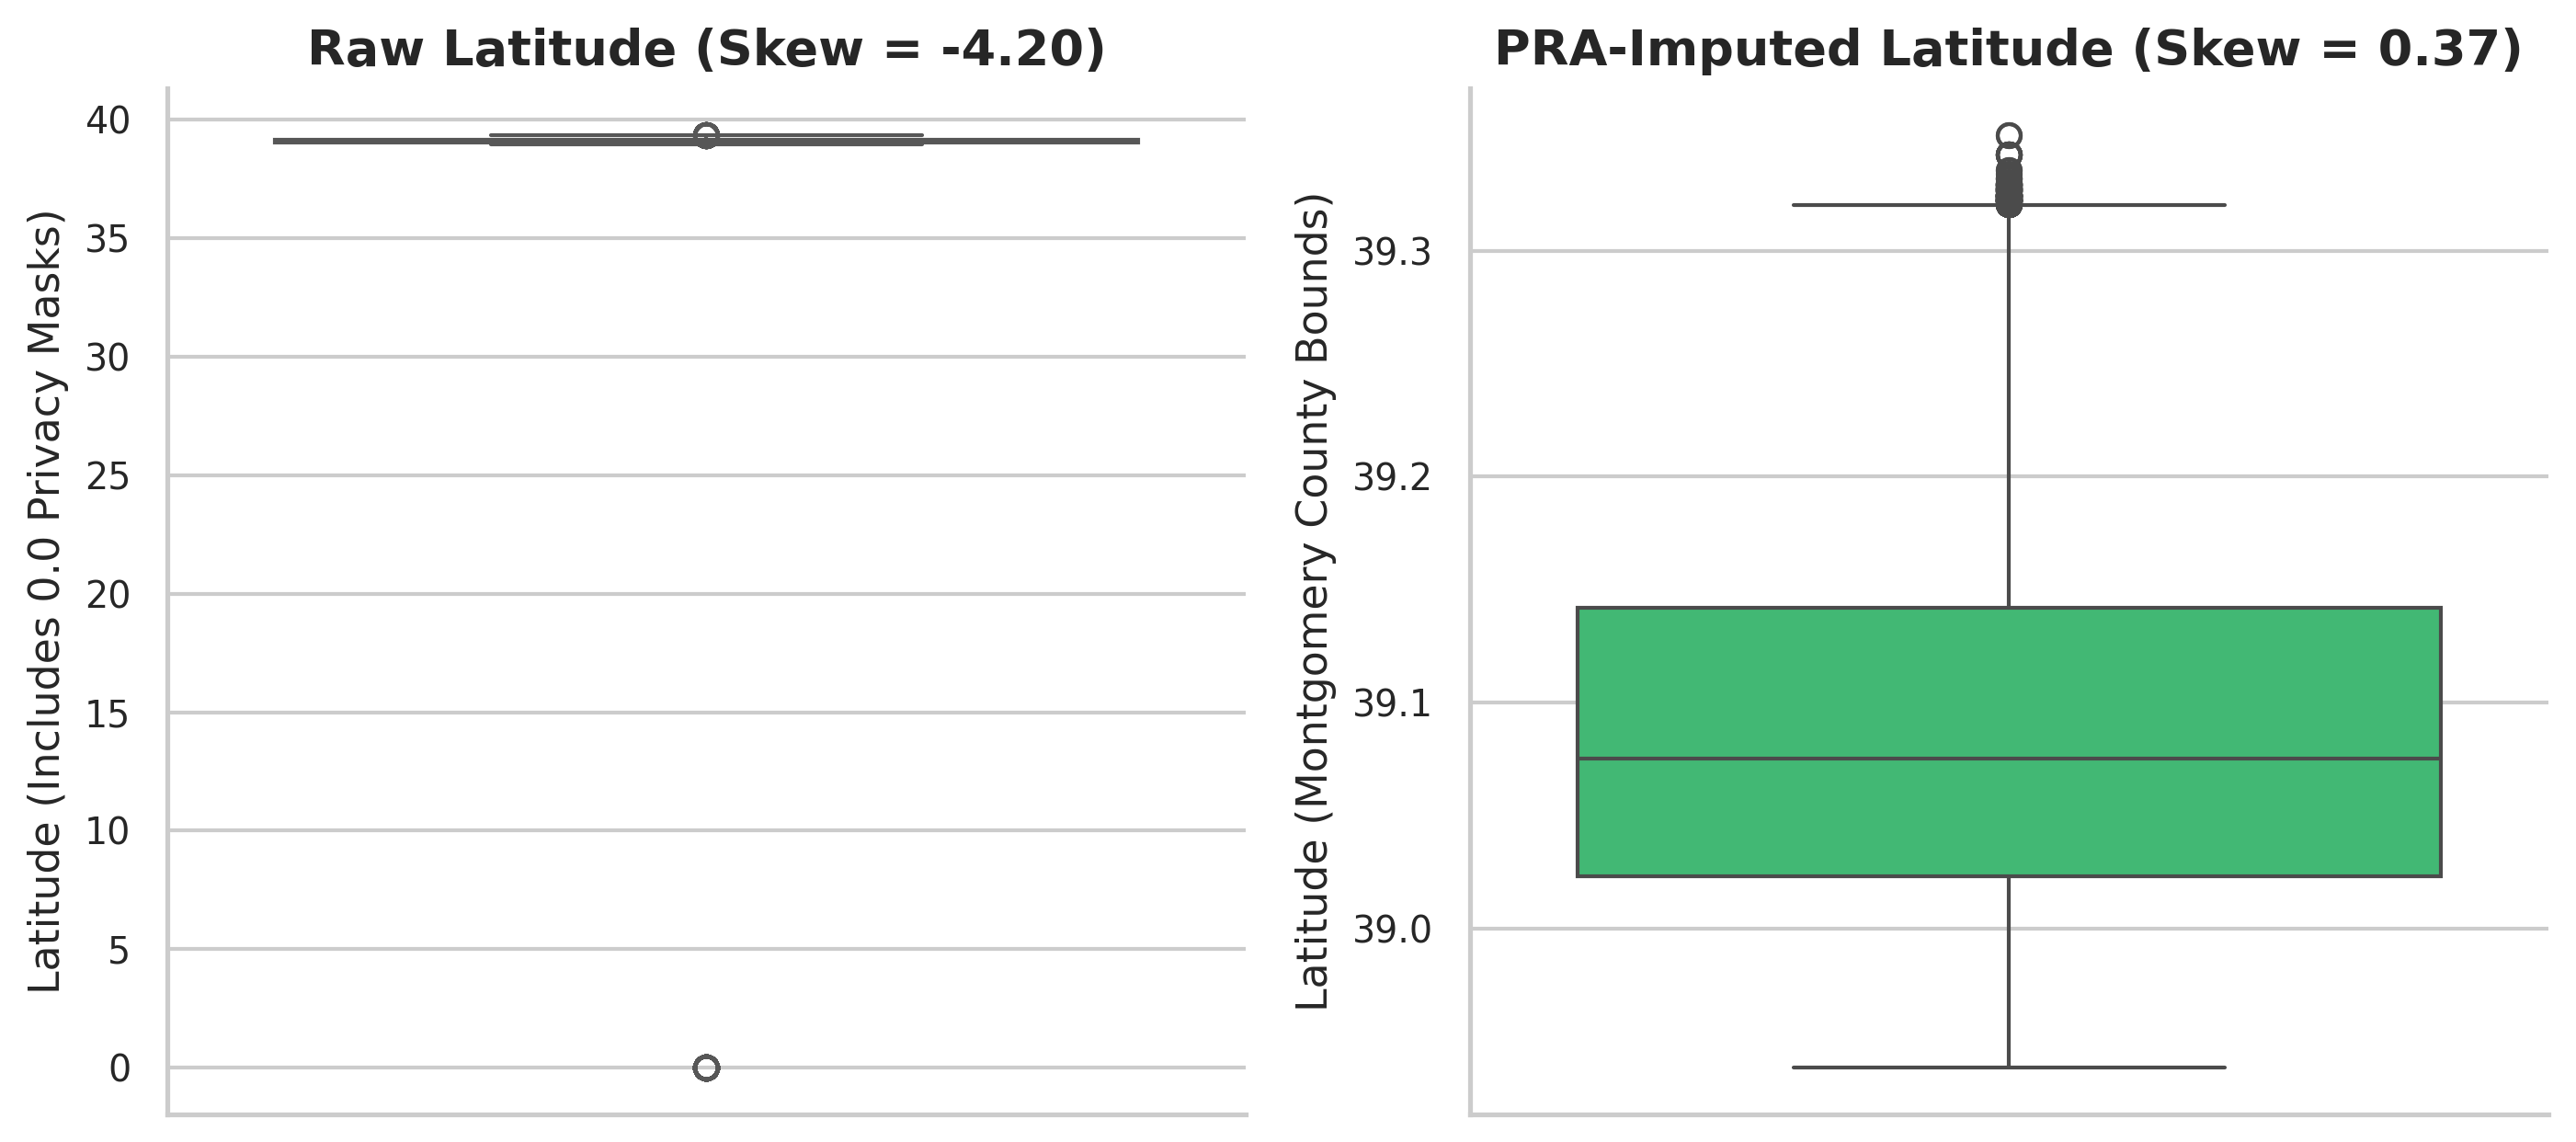

In [51]:
# =========================================================
# RQ5: Privacy-Induced Geospatial Masking Bias
# =========================================================
# RQ5_Viz1: Masked Coordinate Rate (%) by Crime Category
mask_rates = df.groupby('Crime Name1')['Is_Geo_Masked'].mean().mul(100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.barh(mask_rates.index, mask_rates.values, color='#d95f02')
ax.set_title("RQ5.1: Non-Random Privacy Coordinate Masking (0,0) by Crime Type")
ax.set_xlabel("Percentage of Records with Masked (0.0, 0.0) Coordinates (%)")
for bar in bars:
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f"{bar.get_width():.2f}%", va='center', fontsize=9.5, fontweight='bold')
ax.set_xlim(0, mask_rates.max() * 1.2)
save_fig("RQ5_Viz1_Geo_Masking_Bias.png")

# RQ5_Viz2: Before vs After Latitude Distribution (Raw vs PRA-Median Imputed)
raw_lat = pd.to_numeric(raw_df['Latitude'], errors='coerce').dropna()
clean_lat = df['Latitude'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.3))
sns.boxplot(y=raw_lat, ax=axes[0], color='#e74c3c')
axes[0].set_title(f"Raw Latitude (Skew = {raw_lat.skew():.2f})")
axes[0].set_ylabel("Latitude (Includes 0.0 Privacy Masks)")

sns.boxplot(y=clean_lat, ax=axes[1], color='#2ecc71')
axes[1].set_title(f"PRA-Imputed Latitude (Skew = {clean_lat.skew():.2f})")
axes[1].set_ylabel("Latitude (Montgomery County Bounds)")